# 第182章: モード崩壊を測る

## Measuring Mode Collapse: Three Different Failures with One Name

---

### このノートブックの位置づけ

180 で GAN の不安定性を**全体としての近さ**で測りました（エネルギー距離が振動する）。
本章は**どこを落とすか**を測ります。

「モード崩壊」という言葉はよく使われますが、本章の主張はこうです。

> **「モード崩壊」は1つの現象ではない。少なくとも3つの別の失敗が同じ名前で呼ばれており、
> 1つの要約統計量ではそれらを区別できない。**

3つを分けて定義します。

| 型 | 定義 | 日常的な言い方 |
|---|---|---|
| **(a) 完全な取りこぼし** | あるモードにサンプルが実質ゼロ | 「モードが消えた」 |
| **(b) 比率の誤り** | 全モードを出すが割合が真と違う | 「偏っている」 |
| **(c) 多様性の欠如** | モード内で同じ点ばかり出す | 「同じ画像しか出ない」 |

そしてこの3つに、それぞれ別の指標が必要です。
**どの指標がどの型を見逃すか**を実測で確定させるのが本章の仕事です。

196（6系統の総括）での観測を引き継ぎます。8峰リングで GAN は
**4シードすべてで 8/8 被覆したのに占有率が偏り**、
エネルギー距離がシード間で 0.046〜0.216（4.7倍）ばらつきました。
本章ではシードを8本に増やし、何が起きていたかを分解します。

### 学習目標

- [ ] (a)(b)(c) を**構成**して、どの指標が何を検出するかを確定できる
- [ ] 被覆率と占有率だけでは (c) をデータと区別できないことを示せる
- [ ] GAN の設定を変えて3つの型を**作り分け**られる
- [ ] GAN のシード依存を8シードで定量化し、被覆率が検出しないことを示せる
- [ ] 尤度ベース（フロー）と同じ指標で比較し、mode-covering の性質を数値で示せる
- [ ] FID を2次元で原理から実装し、**何に鈍いか**を測定できる
- [ ] 47（MDN の条件付き平均への潰れ）との原因の違いを説明できる

### 前提知識

| ノートブック | トピック |
|---|---|
| **180** | **GAN の基礎（本章の直前）** |
| **196** | **6系統の総括・エネルギー距離・8峰リングでの GAN の実測** |
| 194 | 集計統計が嘘をつく例（本章と同じ型の教訓） |
| 47 | MDN（二乗誤差回帰が正解の平均に潰れる。原因が違う類似現象） |
| 172 | Diffusion Policy（多峰性を表現できる側の実測） |
| 191 | RealNVP（本章の比較対象） |

**難易度**: ★★★★☆ | **所要時間**: 120-150分

> ⏱ **実行時間**: CPU で約4分です。

## 目次

1. [環境セットアップと4つの指標](#setup)
2. [3つの失敗を構成して測る](#constructed)
3. [GAN で3つの型を作り分ける](#gan-configs)
4. [シード依存 — 8シードでのばらつき](#seeds)
5. [尤度ベースとの比較](#flow)
6. [FID の考え方と限界](#fid)
7. [まとめとチートシート](#summary)
8. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップと4つの指標

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)

torch: 2.9.1


### 土俵: 8峰リング

196 と同じ設定です。半径 3 の円周上に 8 つのモードを等間隔に置き、
各モードの標準偏差を 0.25 にします。

- 隣接モード間の距離は約 2.30、標準偏差の **9.2 倍**
- 真の占有率は各モード **0.125**

### 4つの指標

| 指標 | 定義 | 狙う失敗 |
|---|---|---|
| **被覆率** | 占有率が 2% 以上のモードの数（0〜8） | (a) 完全な取りこぼし |
| **占有率の最大偏差** | $\max_k \lvert \text{occ}_k - 0.125 \rvert$ | (b) 比率の誤り |
| **最近傍距離** | 各サンプルから最も近い**他の**サンプルまでの距離の中央値 | (c) 多様性の欠如 |
| **エネルギー距離** | $2\mathbb{E}\|x-y\| - \mathbb{E}\|x-x'\| - \mathbb{E}\|y-y'\|$（196 と同じ） | 全体（どの型にも反応） |

最近傍距離を使う理由を書いておきます。最初は「モード内のペアワイズ距離の平均」を
使おうとしましたが、**壊れていました**。モードへの割り当てが最近傍で決まるので、
どのモードからも遠い点も無理やりどれかに割り当てられ、
「モード内の広がり」と「モードから外れた点の存在」が混ざります。
実測では真のデータ 0.4417 に対してどの失敗例も**それより大きい**値が出て、
多様性の欠如を検出できませんでした。
**各サンプルの最近傍までの距離**なら、重複した点が出れば直接 0 に落ちます。

In [2]:
# ============================================================
# 8峰リングと4つの指標
# ============================================================

angles = torch.arange(8) * 2 * math.pi / 8
RING = torch.stack([3 * angles.cos(), 3 * angles.sin()], -1)
RING_SD = 0.25

def sample_ring(n, seed=0):
    g = torch.Generator().manual_seed(seed)
    k = torch.randint(0, 8, (n,), generator=g)
    return RING[k] + RING_SD * torch.randn(n, 2, generator=g)

X_train = sample_ring(8000, seed=0)
X_ref = sample_ring(10000, seed=2)

gap = float((RING[0] - RING[1]).norm())
print(f"隣接モード間の距離 {gap:.4f} = 標準偏差 {RING_SD} の {gap/RING_SD:.1f} 倍")
print(f"真の占有率は各モード 1/8 = 0.125")
print()


def nearest_mode(x):
    return ((x[:, None, :] - RING[None]) ** 2).sum(-1).argmin(-1)

def coverage_and_occupancy(S, threshold=0.02):
    occ = torch.bincount(nearest_mode(S), minlength=8).float() / len(S)
    return int((occ > threshold).sum()), occ, float((occ - 0.125).abs().max())

def energy_distance(X, Y, n=3000):
    X, Y = X[:n], Y[:n]
    return float(2 * torch.cdist(X, Y).mean()
                 - torch.cdist(X, X).mean() - torch.cdist(Y, Y).mean())

def nn_distance(X, n=3000):
    # 各サンプルから「自分以外の最も近いサンプル」までの距離の中央値
    S = X[:n]
    Dm = torch.cdist(S, S)
    Dm.fill_diagonal_(float("inf"))
    return float(Dm.min(-1).values.median())

def fid_2d(S, ref=None):
    # FID の本質: 特徴空間での2つのガウス近似の間の Fréchet 距離。
    # 2次元なので特徴抽出なしで直接計算できる。
    ref = X_ref if ref is None else ref
    A = S[:5000].numpy().astype(np.float64)
    B = ref[:5000].numpy().astype(np.float64)
    mu1, mu2 = A.mean(0), B.mean(0)
    C1, C2 = np.cov(A, rowvar=False), np.cov(B, rowvar=False)
    cc = sqrtm(C1 @ C2)
    if np.iscomplexobj(cc):
        cc = cc.real          # 行列平方根は数値的に微小な虚部を持つことがある
    return float(((mu1 - mu2) ** 2).sum() + np.trace(C1 + C2 - 2 * cc))

def all_metrics(S):
    cov, occ, maxdev = coverage_and_occupancy(S)
    return dict(cov=cov, occ=occ.numpy(), maxdev=maxdev,
                nn=nn_distance(S), ed=energy_distance(S, X_ref), fid=fid_2d(S))


TRUE = sample_ring(10000, seed=5)
M_TRUE = all_metrics(TRUE)
print("基準（真のサンプル・別のシード）:")
print(f"  被覆 {M_TRUE['cov']}/8  占有率の最大偏差 {M_TRUE['maxdev']:.4f}  "
      f"最近傍距離 {M_TRUE['nn']:.5f}  ED {M_TRUE['ed']:.5f}  FID {M_TRUE['fid']:.5f}")
print("-> モデルの指標はこの値に近いほど良い（0 にはならない。有限標本の誤差）")

隣接モード間の距離 2.2961 = 標準偏差 0.25 の 9.2 倍
真の占有率は各モード 1/8 = 0.125

基準（真のサンプル・別のシード）:
  被覆 8/8  占有率の最大偏差 0.0032  最近傍距離 0.02358  ED 0.00150  FID 0.00402
-> モデルの指標はこの値に近いほど良い（0 にはならない。有限標本の誤差）


<a id="constructed"></a>
## 2. 3つの失敗を構成して測る

GAN を学習させる前に、**3つの失敗を人工的に作って**どの指標が何を検出するかを
確定させます。学習結果で測ると「何型の失敗か」が分からないので、
先に**答えが分かっている例**で指標を校正します。

| 構成 | 作り方 | 意図した型 |
|---|---|---|
| (a) 4モードのみ | 8つのうち 4 つだけから正しい形で生成 | 完全な取りこぼし |
| (b) 比率 4:1 | 全モードから生成するが重みを 0.2 / 0.05 の交互に | 比率の誤り |
| (c) モード中心に潰す | 占有率は正しく 1/8 ずつ、ただし各点をモード中心に（標準偏差 0.002） | 多様性の欠如 |

**予想**: 被覆率は (a) だけを検出し、最大偏差は (b) だけを検出し、
最近傍距離は (c) だけを検出する。エネルギー距離は全部に反応する。

In [3]:
# ============================================================
# 3つの失敗を構成する
# ============================================================

g = torch.Generator().manual_seed(11)

# (a) 完全な取りこぼし: 8つのうち4つだけ
k_a = torch.randint(0, 4, (10000,), generator=g)
CASE_A = RING[k_a] + RING_SD * torch.randn(10000, 2, generator=g)

# (b) 比率の誤り: 全モードを出すが 4:1 に偏らせる
w = torch.tensor([0.2, 0.05, 0.2, 0.05, 0.2, 0.05, 0.2, 0.05])
k_b = torch.multinomial(w, 10000, replacement=True, generator=g)
CASE_B = RING[k_b] + RING_SD * torch.randn(10000, 2, generator=g)

# (c) 多様性の欠如: 占有率は正しいが各点がモード中心に潰れている
k_c = torch.randint(0, 8, (10000,), generator=g)
CASE_C = RING[k_c] + 0.002 * torch.randn(10000, 2, generator=g)

constructed = [("真のデータ", TRUE), ("(a) 4モードのみ", CASE_A),
               ("(b) 比率 4:1", CASE_B), ("(c) モード中心に潰す", CASE_C)]

print(f"{'ケース':<24}{'被覆':>6}{'最大偏差':>10}{'最近傍距離':>12}{'ED':>10}{'FID':>10}")
print("-" * 72)
built = {}
for tag, S in constructed:
    m = all_metrics(S)
    built[tag] = m
    print(f"{tag:<24}{m['cov']:>6}{m['maxdev']:>10.4f}{m['nn']:>12.5f}"
          f"{m['ed']:>10.5f}{m['fid']:>10.5f}")
print("-" * 72)
print()
print("各ケースの占有率（真は各 0.125）:")
for tag, _ in constructed:
    print(f"  {tag:<24} {np.round(built[tag]['occ'], 3)}")

ケース                         被覆      最大偏差       最近傍距離        ED       FID
------------------------------------------------------------------------
真のデータ                        8    0.0032     0.02358   0.00150   0.00402
(a) 4モードのみ                   4    0.1268     0.01628   1.05615   5.54549
(b) 比率 4:1                   8    0.0816     0.02097   0.03685   0.00159
(c) モード中心に潰す                 8    0.0038     0.00000   0.02530   0.00420
------------------------------------------------------------------------

各ケースの占有率（真は各 0.125）:
  真のデータ                    [0.125 0.122 0.123 0.126 0.126 0.124 0.128 0.126]
  (a) 4モードのみ               [0.251 0.246 0.252 0.251 0.    0.    0.    0.   ]
  (b) 比率 4:1               [0.201 0.048 0.207 0.049 0.2   0.05  0.194 0.052]
  (c) モード中心に潰す             [0.121 0.128 0.128 0.122 0.128 0.124 0.127 0.122]


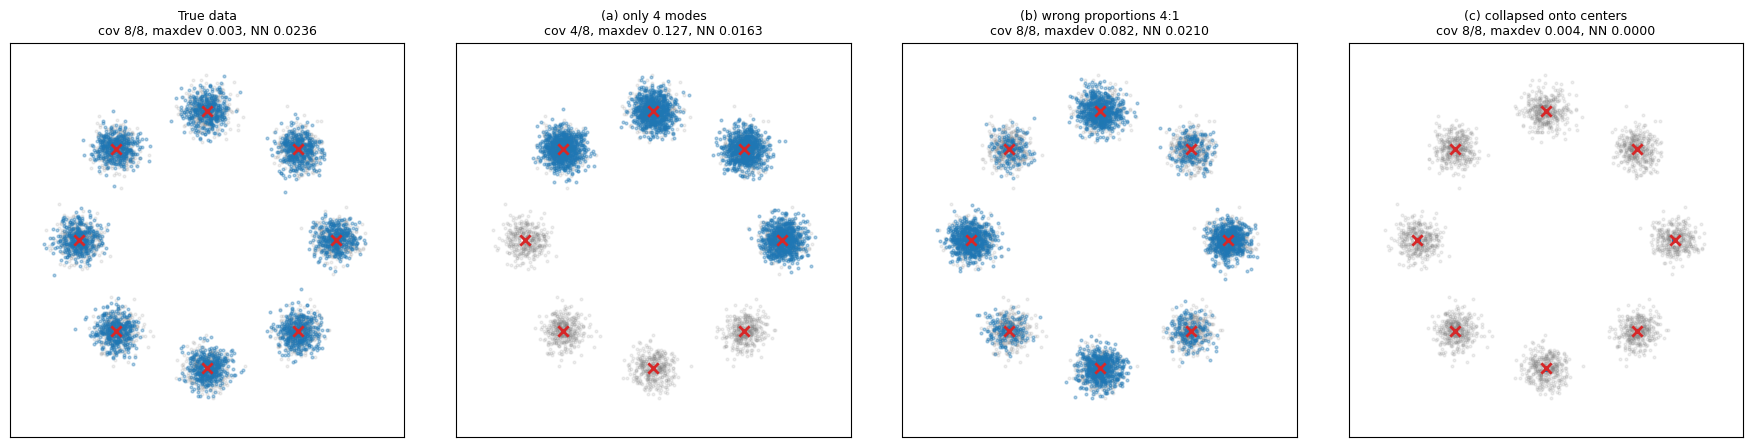

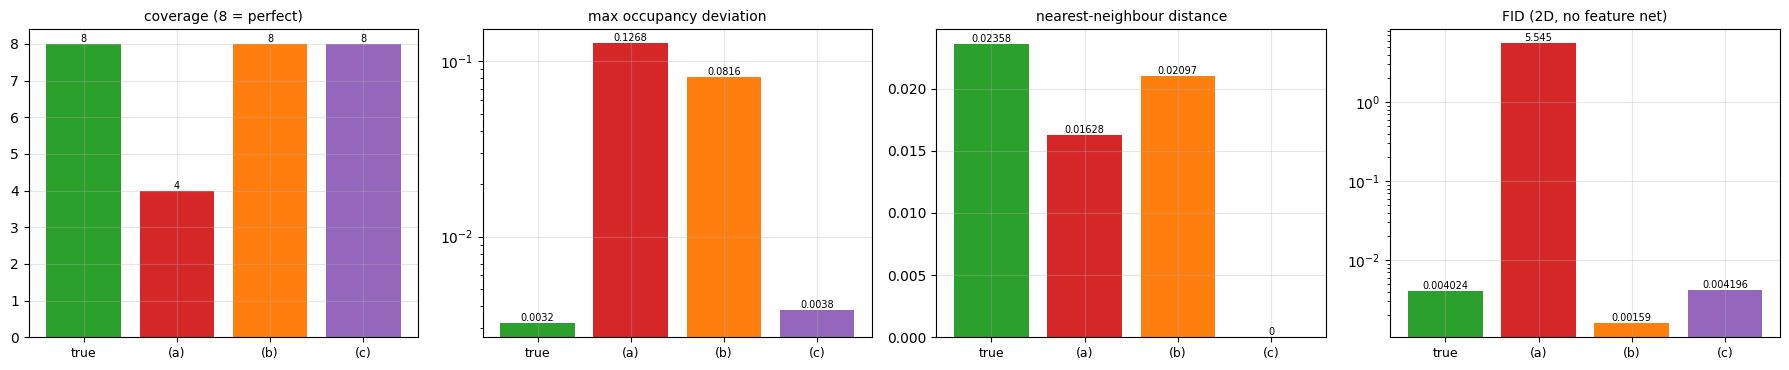

In [4]:
# ============================================================
# 図: 構成した3つの失敗
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
labels_en = {"真のデータ": "True data", "(a) 4モードのみ": "(a) only 4 modes",
             "(b) 比率 4:1": "(b) wrong proportions 4:1",
             "(c) モード中心に潰す": "(c) collapsed onto centers"}
for ax, (tag, S) in zip(axes, constructed):
    sn = S[:3000].numpy()
    ax.scatter(X_ref[:3000, 0], X_ref[:3000, 1], s=4, alpha=0.12, color="tab:gray")
    ax.scatter(sn[:, 0], sn[:, 1], s=4, alpha=0.35, color="tab:blue")
    ax.scatter(RING[:, 0], RING[:, 1], s=55, marker="x", color="tab:red", lw=2)
    ax.set_xlim(-4.6, 4.6)
    ax.set_ylim(-4.6, 4.6)
    ax.set_aspect("equal")
    m = built[tag]
    ax.set_title(f"{labels_en[tag]}\ncov {m['cov']}/8, maxdev {m['maxdev']:.3f}, "
                 f"NN {m['nn']:.4f}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

# 指標ごとの検出能力
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
keys = [("cov", "coverage (8 = perfect)", False),
        ("maxdev", "max occupancy deviation", True),
        ("nn", "nearest-neighbour distance", True),
        ("fid", "FID (2D, no feature net)", True)]
names = [labels_en[t] for t, _ in constructed]
for ax, (k, title, logscale) in zip(axes, keys):
    vals = [built[t][k] for t, _ in constructed]
    colors = ["tab:green"] + ["tab:red", "tab:orange", "tab:purple"]
    ax.bar(range(4), vals, color=colors)
    ax.set_xticks(range(4))
    ax.set_xticklabels(["true", "(a)", "(b)", "(c)"], fontsize=9)
    if logscale and min(vals) > 0:
        ax.set_yscale("log")
    ax.set_title(title, fontsize=10)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.4g}", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

### 読み取れること — 予想は半分外れた

| ケース | 被覆 | 最大偏差 | 最近傍距離 | ED | FID |
|---|---|---|---|---|---|
| 真のデータ | 8 | 0.0032 | 0.02358 | 0.00150 | 0.00402 |
| (a) 4モードのみ | **4** | 0.1268 | 0.01628 | **1.05615** | **5.54549** |
| (b) 比率 4:1 | 8 | **0.0816** | 0.02097 | 0.03685 | **0.00159** |
| (c) モード中心に潰す | 8 | **0.0038** | **0.00000** | 0.02530 | **0.00420** |

**(c) の行が本章の核心です。**

- 被覆率 **8/8** — 完璧
- 占有率の最大偏差 **0.0038** — 真のデータの 0.0032 とほぼ同じ（統計誤差の範囲）
- **FID 0.00420** — 真のデータの 0.00402 と**区別できない**（1.04 倍）
- しかし最近傍距離は **0.00000**（真のデータは 0.02358）

つまり**被覆率・占有率・FID の3つすべてが「問題なし」と判定する分布が、
実際には 8 点にしか確率を置いていません**。

**(b) でも FID は効きません。** FID 0.00159 は真のデータの 0.00402 より
**小さい（良い）**値です。比率を 4:1 にずらしても、対称な配置なので
平均はほぼ動かず、共分散も大きくは変わりません。

**予想が外れた点**: FID が (c) を検出すると予想していました。
FID は共分散を見るので、潰れた分布なら共分散が小さくなって差が出るはず、という読みでした。
実測では **(b) も (c) も真のデータと区別できません**。外れた理由は計算してみると明らかです。

| 共分散への寄与 | 大きさ |
|---|---|
| モード間（半径 3 の円周上の配置） | 対角成分に $\approx 3^2/2 = 4.5$ |
| モード内（$\sigma = 0.25$） | 対角成分に $0.25^2 = 0.0625$ |

**モード内の広がりは共分散の 1.4% しか占めません。**
それを 0 にしても、ガウス近似の2つのモーメントはほとんど変わりません。

一方エネルギー距離は、(b) で 0.03685 対 0.00150 で **25 倍**、
(c) で 0.02530 対 0.00150 で **17 倍**動きます。
**同じ失敗に対して、FID は 1 倍、エネルギー距離は 20 倍前後**という差です。

**FID が強く反応したのは (a) だけ**（5.54549、真のデータの **1378 倍**）です。
4つのモードを落とすと平均が原点から外れ、共分散の形も変わるからです。

> 📌 **FID は「モーメントが合っているか」しか見ていません。**
> 多峰分布では、モード内の構造も比率の偏りも、共分散のごく一部にしか現れません。
> 本章の実測では、**(b) の FID が実データより良い値になりました**。
> これは2次元だから極端に見えますが、原理は高次元でも同じです
> （画像の FID では Inception の特徴空間で同じガウス近似をしています）。

<a id="gan-configs"></a>
## 3. GAN で3つの型を作り分ける

構成した例で指標を校正したので、次は**実際の GAN で3つの型が出るか**を見ます。
設定を4つ用意します。どの設定がどの型を生むかは**測ってから決めます**
（予想と違ってよい。違ったらそう書く）。

| 設定 | 変更点 | 予想した型 |
|---|---|---|
| 標準 | 潜在2次元・隠れ128・両方 lr 2e-4 | 196 の再現（(b)） |
| 潜在1次元 | 潜在を1次元に | (a) 表現力不足で取りこぼし |
| 生成器を極小 | 生成器の隠れ層を 8 に | (a) |
| D の lr を10倍 | 判別器だけ lr 2e-3 | (b) 均衡が崩れて偏る |

各設定 3 シード。

In [5]:
# ============================================================
# GAN の実装
# ============================================================

class Generator(nn.Module):
    def __init__(self, z_dim=2, hidden=128):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2))

    def forward(self, n, gen=None):
        return self.net(torch.randn(n, self.z_dim, generator=gen))


class Discriminator(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


bce = nn.BCEWithLogitsLoss()

def train_gan(z_dim=2, g_hidden=128, lr_g=2e-4, lr_d=2e-4,
              steps=6000, seed=0, batch=256):
    torch.manual_seed(seed)
    G = Generator(z_dim, g_hidden)
    D = Discriminator()
    og = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    for _ in range(steps):
        x_real = X_train[torch.randint(0, len(X_train), (batch,))]
        x_fake = G(batch).detach()
        ld = bce(D(x_real), torch.ones(batch)) + bce(D(x_fake), torch.zeros(batch))
        od.zero_grad()
        ld.backward()
        od.step()
        og.zero_grad()
        bce(D(G(batch)), torch.ones(batch)).backward()   # 非飽和損失（180 第3節）
        og.step()
    return G


CONFIGS = [("標準", dict()),
           ("潜在1次元", dict(z_dim=1)),
           ("生成器を極小（隠れ8）", dict(g_hidden=8)),
           ("D の lr を10倍", dict(lr_d=2e-3))]

t0 = time.time()
gan_results = {}
print(f"{'設定':<24}{'被覆':>7}{'最大偏差':>10}{'最近傍距離':>12}{'ED':>10}{'FID':>10}")
print("-" * 73)
for tag, kw in CONFIGS:
    runs = []
    for sd in [0, 1, 2]:
        G = train_gan(seed=sd, **kw)
        with torch.no_grad():
            runs.append(all_metrics(G(10000)))
    agg = {k: float(np.mean([r[k] for r in runs]))
           for k in ["cov", "maxdev", "nn", "ed", "fid"]}
    gan_results[tag] = (agg, runs)
    print(f"{tag:<24}{agg['cov']:>7.1f}{agg['maxdev']:>10.4f}{agg['nn']:>12.5f}"
          f"{agg['ed']:>10.5f}{agg['fid']:>10.5f}")
print("-" * 73)
print(f"{'真のデータ':<24}{M_TRUE['cov']:>7}{M_TRUE['maxdev']:>10.4f}"
      f"{M_TRUE['nn']:>12.5f}{M_TRUE['ed']:>10.5f}{M_TRUE['fid']:>10.5f}")
print(f"計算時間 {time.time() - t0:.0f}s")
print()
print("占有率（各設定の seed 0）:")
for tag, _ in CONFIGS:
    print(f"  {tag:<24} {np.round(gan_results[tag][1][0]['occ'], 3)}")

設定                           被覆      最大偏差       最近傍距離        ED       FID
-------------------------------------------------------------------------


標準                          8.0    0.1068     0.01816   0.09434   0.27302


潜在1次元                       8.0    0.1394     0.00190   0.26447   0.75203


生成器を極小（隠れ8）                 4.7    0.3875     0.01451   1.59440   7.05378


D の lr を10倍                 8.0    0.1489     0.02394   0.18537   0.51250
-------------------------------------------------------------------------
真のデータ                         8    0.0032     0.02358   0.00150   0.00402
計算時間 80s

占有率（各設定の seed 0）:
  標準                       [0.237 0.054 0.238 0.052 0.235 0.062 0.062 0.062]
  潜在1次元                    [0.247 0.278 0.084 0.069 0.077 0.08  0.078 0.087]
  生成器を極小（隠れ8）              [0.263 0.209 0.196 0.131 0.063 0.025 0.012 0.101]
  D の lr を10倍              [0.097 0.103 0.101 0.099 0.099 0.15  0.262 0.089]


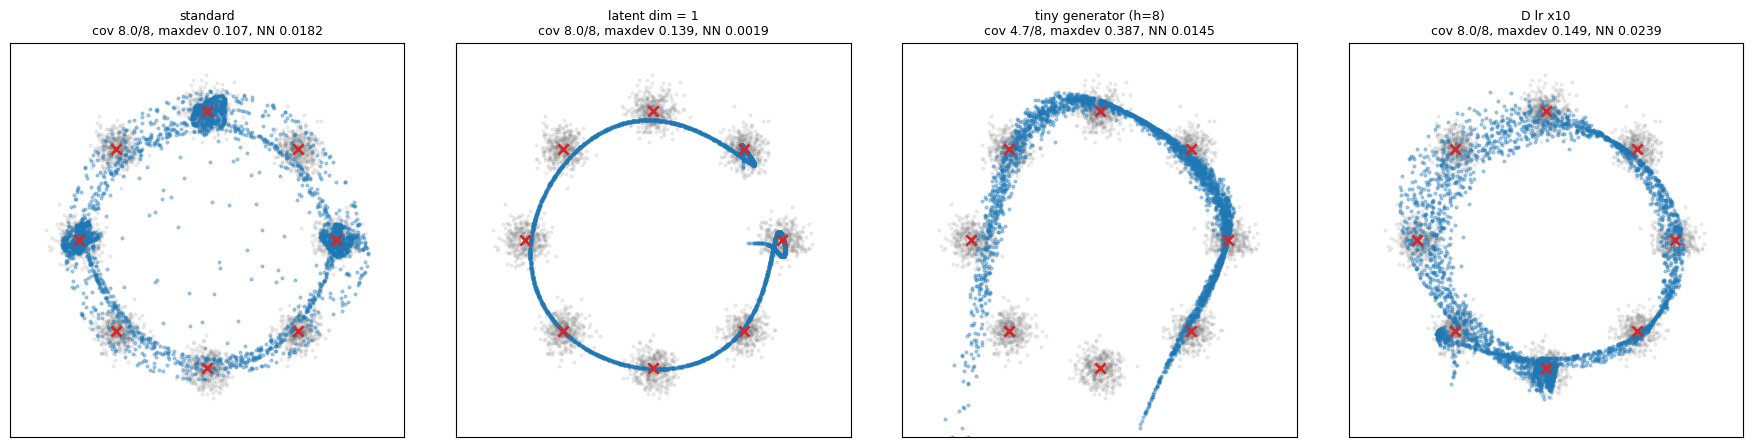

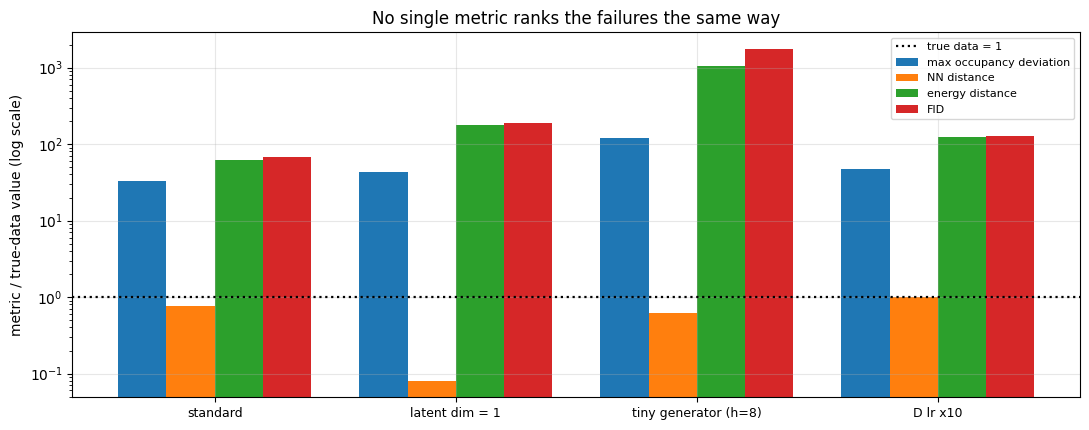

In [6]:
# ============================================================
# 図: 設定ごとの失敗の型
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
cfg_labels = {"標準": "standard", "潜在1次元": "latent dim = 1",
              "生成器を極小（隠れ8）": "tiny generator (h=8)",
              "D の lr を10倍": "D lr x10"}
for ax, (tag, kw) in zip(axes, CONFIGS):
    G = train_gan(seed=0, **kw)
    with torch.no_grad():
        S = G(3000)
    sn = S.numpy()
    ax.scatter(X_ref[:3000, 0], X_ref[:3000, 1], s=4, alpha=0.12, color="tab:gray")
    ax.scatter(sn[:, 0], sn[:, 1], s=4, alpha=0.35, color="tab:blue")
    ax.scatter(RING[:, 0], RING[:, 1], s=55, marker="x", color="tab:red", lw=2)
    ax.set_xlim(-4.6, 4.6)
    ax.set_ylim(-4.6, 4.6)
    ax.set_aspect("equal")
    a = gan_results[tag][0]
    ax.set_title(f"{cfg_labels[tag]}\ncov {a['cov']:.1f}/8, maxdev {a['maxdev']:.3f}, "
                 f"NN {a['nn']:.4f}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

# 指標の正規化比較（真のデータを 1 とした比）
fig, ax = plt.subplots(figsize=(11, 4.4))
tags = [t for t, _ in CONFIGS]
metric_keys = [("maxdev", "max occupancy deviation"), ("nn", "NN distance"),
               ("ed", "energy distance"), ("fid", "FID")]
width = 0.2
xpos = np.arange(len(tags))
for i, (k, lab) in enumerate(metric_keys):
    vals = [gan_results[t][0][k] / M_TRUE[k] for t in tags]
    ax.bar(xpos + (i - 1.5) * width, vals, width, label=lab)
ax.axhline(1.0, color="k", ls=":", lw=1.6, label="true data = 1")
ax.set_yscale("log")
ax.set_xticks(xpos)
ax.set_xticklabels([cfg_labels[t] for t in tags], fontsize=9)
ax.set_ylabel("metric / true-data value (log scale)")
ax.set_title("No single metric ranks the failures the same way")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 読み取れること — 3つの型が実際に出た

| 設定 | 被覆 | 最大偏差 | 最近傍距離 | ED | FID | 判定された型 |
|---|---|---|---|---|---|---|
| 標準 | 8.0 | 0.1068 | 0.01816 | 0.09434 | 0.27302 | **(b)** 比率の誤り |
| 潜在1次元 | 8.0 | 0.1394 | **0.00190** | 0.26447 | 0.75203 | **(c)** 多様性の欠如 |
| 生成器を極小 | **4.7** | **0.3875** | 0.01451 | 1.59440 | 7.05378 | **(a)** 取りこぼし |
| D の lr を10倍 | 8.0 | 0.1489 | 0.02394 | 0.18537 | 0.51250 | (b) 比率の誤り |
| 真のデータ | 8 | 0.0032 | 0.02358 | 0.00150 | 0.00402 | — |

**予想と合っていた点**: 生成器を極小にすると (a) が出ました（被覆 4.7/8）。
標準設定は 196 の観測どおり (b) です（占有率 `[0.237, 0.054, 0.238, 0.052, 0.235, 0.062, 0.062, 0.062]`
— 4つが 0.24 前後、4つが 0.06 前後で**4倍**の偏り）。

**予想と違っていた点**: 潜在1次元は (a) だと予想しましたが、
**被覆は 8/8 で (c) が出ました**。最近傍距離 0.00190 は真のデータの 0.02358 の
**12分の1**です。

機構は納得できます。1次元の潜在を2次元に写すと、出力は**曲線**になります。
曲線は8つのモードすべての近くを通れるので**被覆率は満点**になりますが、
曲線上の点なので**局所的には1次元しかない**（面を埋めない）。
これが最近傍距離に出ます。

> 💡 **「潜在次元を増やせば多様性が出る」の数値的な裏づけ**です。
> ただし本章の実測は $d=2$ のデータに対する $z$ の次元の話で、
> 高次元画像で同じ比率が成り立つとは限りません（$z$ の次元はむしろ
> データの多様体の次元に合わせるべきで、増やしすぎると別の問題が出ます）。

<a id="seeds"></a>
## 4. シード依存 — 8シードでのばらつき

196 では標準設定の GAN を4シード回し、エネルギー距離が 0.046〜0.216（4.7倍）
ばらつくことを測りました。シードを 8 本に増やして分布を見ます。

**ここで確認したいのは「どの指標がばらつくか」です。**
被覆率がばらつかないなら、被覆率だけを報告する評価は
**GAN の不安定性を一切検出できない**ことになります。

In [7]:
# ============================================================
# 8シードでのばらつき
# ============================================================

t0 = time.time()
seed_rows = []
for sd in range(8):
    G = train_gan(seed=sd)
    with torch.no_grad():
        m = all_metrics(G(10000))
    seed_rows.append(m)
    print(f"seed={sd}: 被覆 {m['cov']}/8  最大偏差 {m['maxdev']:.4f}  "
          f"最近傍 {m['nn']:.5f}  ED {m['ed']:.5f}  FID {m['fid']:.5f}")
print(f"計算時間 {time.time() - t0:.0f}s")
print()

eds = [m["ed"] for m in seed_rows]
fids = [m["fid"] for m in seed_rows]
mds = [m["maxdev"] for m in seed_rows]
nns = [m["nn"] for m in seed_rows]
covs = [m["cov"] for m in seed_rows]

print("8シードでの各指標のばらつき:")
print(f"  被覆率      : すべて {set(covs)}  -> ばらつき 0")
print(f"  最大偏差    : {min(mds):.4f} 〜 {max(mds):.4f}  = {max(mds)/min(mds):.1f} 倍")
print(f"  最近傍距離  : {min(nns):.5f} 〜 {max(nns):.5f}  = {max(nns)/min(nns):.1f} 倍")
print(f"  ED          : {min(eds):.5f} 〜 {max(eds):.5f}  = {max(eds)/min(eds):.1f} 倍"
      f"（平均 {np.mean(eds):.5f} 標準偏差 {np.std(eds):.5f}）")
print(f"  FID         : {min(fids):.5f} 〜 {max(fids):.5f}  = {max(fids)/min(fids):.1f} 倍")
print()
print(f"196 の4シードでは ED が 0.046〜0.216（4.7倍）。8シードに広げると "
      f"{min(eds):.3f}〜{max(eds):.3f}（{max(eds)/min(eds):.1f}倍）。")

seed=0: 被覆 8/8  最大偏差 0.1130  最近傍 0.01730  ED 0.13647  FID 0.36751


seed=1: 被覆 8/8  最大偏差 0.0951  最近傍 0.01806  ED 0.04115  FID 0.01305


seed=2: 被覆 8/8  最大偏差 0.1124  最近傍 0.01911  ED 0.10540  FID 0.43850


seed=3: 被覆 8/8  最大偏差 0.0909  最近傍 0.01705  ED 0.17088  FID 0.55797


seed=4: 被覆 8/8  最大偏差 0.1299  最近傍 0.01747  ED 0.15615  FID 0.65725


seed=5: 被覆 8/8  最大偏差 0.0931  最近傍 0.01754  ED 0.08908  FID 0.22915


seed=6: 被覆 8/8  最大偏差 0.1395  最近傍 0.01992  ED 0.31920  FID 1.12094


seed=7: 被覆 8/8  最大偏差 0.0786  最近傍 0.01926  ED 0.18422  FID 0.68344
計算時間 58s

8シードでの各指標のばらつき:
  被覆率      : すべて {8}  -> ばらつき 0
  最大偏差    : 0.0786 〜 0.1395  = 1.8 倍
  最近傍距離  : 0.01705 〜 0.01992  = 1.2 倍
  ED          : 0.04115 〜 0.31920  = 7.8 倍（平均 0.15032 標準偏差 0.07746）
  FID         : 0.01305 〜 1.12094  = 85.9 倍

196 の4シードでは ED が 0.046〜0.216（4.7倍）。8シードに広げると 0.041〜0.319（7.8倍）。


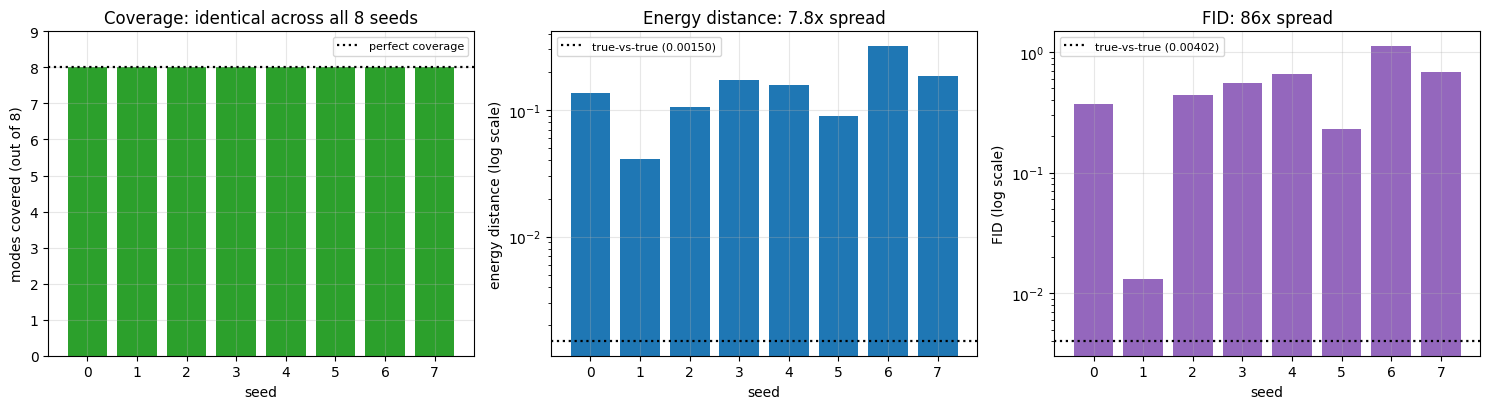

In [8]:
# ============================================================
# 図: シード依存
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].bar(range(8), covs, color="tab:green")
axes[0].axhline(8, color="k", ls=":", lw=1.6, label="perfect coverage")
axes[0].set_ylim(0, 9)
axes[0].set_xlabel("seed")
axes[0].set_ylabel("modes covered (out of 8)")
axes[0].set_title("Coverage: identical across all 8 seeds")
axes[0].legend(fontsize=8)

axes[1].bar(range(8), eds, color="tab:blue")
axes[1].axhline(M_TRUE["ed"], color="k", ls=":", lw=1.6,
                label=f"true-vs-true ({M_TRUE['ed']:.5f})")
axes[1].set_yscale("log")
axes[1].set_xlabel("seed")
axes[1].set_ylabel("energy distance (log scale)")
axes[1].set_title(f"Energy distance: {max(eds)/min(eds):.1f}x spread")
axes[1].legend(fontsize=8)

axes[2].bar(range(8), fids, color="tab:purple")
axes[2].axhline(M_TRUE["fid"], color="k", ls=":", lw=1.6,
                label=f"true-vs-true ({M_TRUE['fid']:.5f})")
axes[2].set_yscale("log")
axes[2].set_xlabel("seed")
axes[2].set_ylabel("FID (log scale)")
axes[2].set_title(f"FID: {max(fids)/min(fids):.0f}x spread")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 被order率は何も検出しない

| 指標 | 8シードでの範囲 | 比 |
|---|---|---|
| **被覆率** | **8/8（全シード同一）** | **ばらつき 0** |
| 占有率の最大偏差 | 0.0786 〜 0.1395 | 1.8 倍 |
| 最近傍距離 | 0.01705 〜 0.01992 | 1.2 倍 |
| **エネルギー距離** | 0.04115 〜 0.31920 | **7.8 倍** |
| **FID** | 0.01305 〜 1.12094 | **86 倍** |

**被覆率は8シードすべてで 8/8 です。**
つまり「モードを被覆できているか」だけを報告する評価では、
**GAN の品質が 7.8 倍ばらついていることを一切検出できません**。

逆に FID は **86 倍**ばらつきます。seed 1 の FID は 0.01305 で、
真のデータの 0.00402 の 3.2 倍まで迫ります。
**単一シードで FID を報告すれば、同じ手法を「ほぼ完璧」とも「2桁悪い」とも
主張できてしまいます。**

> ⚠️ **GAN の単一シードの結果は、良くても悪くても信用できません。**
> 196 で4シードから得た「4.7倍」は、8シードに広げると 7.8 倍になりました。
> シード数を増やすほど範囲は広がる（極値統計なので当然）ので、
> **報告すべきは範囲でなく平均と標準偏差**です
> （本章の実測では平均 0.15032、標準偏差 0.07746）。

> 📌 **194 第4節と同じ型の教訓です。** あちらでは
> 「モード占有率の最大偏差 0.012 で完璧に見えるのに、1チェーンの訪問モード数は 1.03/4」
> でした。こちらは「被覆率 8/8 で完璧に見えるのに、エネルギー距離は 7.8 倍ばらつく」。
> **1つの要約統計量で分布の一致を主張してはいけない。**

<a id="flow"></a>
## 5. 尤度ベースとの比較

196 で整理した非対称性を思い出します。

| 指標 | 厳しい誤り | 甘い誤り |
|---|---|---|
| 対数尤度（$\mathrm{KL}(p_{\text{data}}\|p_\theta)$ の最小化） | **データを見逃す**（mode-covering） | 余計な場所に確率を置く |
| サンプル品質 | 余計な場所に確率を置く | データを見逃す |

尤度を最大化するモデルは**データのある場所を覆わないと大きく罰される**ので、
(a) 完全な取りこぼしを起こしにくいはずです。

同じ8峰リングに **RealNVP**（191 の実装）を当てて、同じ指標で測ります。

In [9]:
# ============================================================
# RealNVP（191 の実装）を同じ土俵で
# ============================================================

class AffineCoupling(nn.Module):
    def __init__(self, mask, hidden=64):
        super().__init__()
        self.register_buffer("mask", mask.float())
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 4))
        self.net[-1].weight.data.zero_()
        self.net[-1].bias.data.zero_()

    def _st(self, x):
        s, t = self.net(x * self.mask).chunk(2, -1)
        return torch.tanh(s) * 2.0 * (1 - self.mask), t * (1 - self.mask)

    def forward(self, x):
        s, t = self._st(x)
        return x * self.mask + (1 - self.mask) * (x * s.exp() + t), s.sum(-1)

    def inverse(self, z):
        s, t = self._st(z)
        return z * self.mask + (1 - self.mask) * ((z - t) * (-s).exp())


class RealNVP(nn.Module):
    def __init__(self, n_layers=8):
        super().__init__()
        m0 = torch.tensor([1.0, 0.0])
        self.layers = nn.ModuleList(
            [AffineCoupling(m0 if i % 2 == 0 else 1 - m0) for i in range(n_layers)])

    def log_prob(self, x):
        ld = torch.zeros(len(x))
        for l in self.layers:
            x, d = l(x)
            ld = ld + d
        return (-0.5 * x**2 - 0.5 * math.log(2 * math.pi)).sum(-1) + ld

    @torch.no_grad()
    def sample(self, n):
        z = torch.randn(n, 2)
        for l in reversed(self.layers):
            z = l.inverse(z)
        return z


t0 = time.time()
flow_rows = []
for sd in [0, 1, 2]:
    torch.manual_seed(sd)
    F = RealNVP()
    opt = torch.optim.Adam(F.parameters(), lr=5e-3)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=2000)
    for _ in range(2000):
        loss = -F.log_prob(X_train).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sch.step()
    m = all_metrics(F.sample(10000))
    flow_rows.append(m)
    print(f"RealNVP seed={sd}: 被覆 {m['cov']}/8  最大偏差 {m['maxdev']:.4f}  "
          f"最近傍 {m['nn']:.5f}  ED {m['ed']:.5f}  FID {m['fid']:.5f}")
print(f"計算時間 {time.time() - t0:.0f}s")

f_eds = [m["ed"] for m in flow_rows]
f_mds = [m["maxdev"] for m in flow_rows]
print()
print(f"{'':<16}{'被覆':>8}{'最大偏差':>12}{'ED 平均':>12}{'ED 標準偏差':>14}")
print("-" * 64)
print(f"{'GAN（8シード）':<16}{'8/8 全部':>8}{np.mean(mds):>12.4f}"
      f"{np.mean(eds):>12.5f}{np.std(eds):>14.5f}")
print(f"{'RealNVP（3シード）':<16}{'8/8 全部':>8}{np.mean(f_mds):>12.4f}"
      f"{np.mean(f_eds):>12.5f}{np.std(f_eds):>14.5f}")
print(f"{'真のデータ':<16}{'8/8':>8}{M_TRUE['maxdev']:>12.4f}{M_TRUE['ed']:>12.5f}{'—':>14}")
print("-" * 64)
print()
print(f"ED の平均で {np.mean(eds)/np.mean(f_eds):.1f} 倍、"
      f"標準偏差で {np.std(eds)/np.std(f_eds):.1f} 倍の差")
print(f"最大偏差の平均で {np.mean(mds)/np.mean(f_mds):.1f} 倍の差")

RealNVP seed=0: 被覆 8/8  最大偏差 0.0181  最近傍 0.02793  ED 0.00410  FID 0.00418


RealNVP seed=1: 被覆 8/8  最大偏差 0.0153  最近傍 0.03230  ED 0.01613  FID 0.01051


RealNVP seed=2: 被覆 8/8  最大偏差 0.0241  最近傍 0.02561  ED 0.00827  FID 0.01402
計算時間 81s

                      被覆        最大偏差       ED 平均       ED 標準偏差
----------------------------------------------------------------
GAN（8シード）         8/8 全部      0.1066     0.15032       0.07746
RealNVP（3シード）     8/8 全部      0.0192     0.00950       0.00499
真のデータ                8/8      0.0032     0.00150             —
----------------------------------------------------------------

ED の平均で 15.8 倍、標準偏差で 15.5 倍の差
最大偏差の平均で 5.6 倍の差


### 読み取れること — 絶対値で比べる

| | 被覆 | 最大偏差（平均） | ED（平均） | ED（標準偏差） |
|---|---|---|---|---|
| GAN（8シード） | 8/8 全部 | 0.1066 | 0.15032 | 0.07746 |
| RealNVP（3シード） | 8/8 全部 | 0.0192 | 0.00950 | 0.00499 |
| 真のデータ | 8/8 | 0.0032 | 0.00150 | — |

**RealNVP は ED の平均で 15.8 倍、標準偏差で 15.5 倍良い**です。
占有率の最大偏差も 5.6 倍良く、真のデータの 0.0032 に近づいています。

ただし**比で見ると誤解します**。RealNVP の ED のばらつきは
0.00410〜0.01613 で **3.9 倍**、GAN は 7.8 倍です。
「3.9 倍と 7.8 倍なら 2 倍の違い」と読めてしまいます。
しかし**絶対値の標準偏差は 0.00499 対 0.07746 で 15.5 倍**違います。

> ⚠️ **ばらつきを比で報告すると小さく見えます。**
> 良いモデルは平均が小さいので、同じ絶対ばらつきでも比は大きく出ます。
> **ばらつきは絶対値（標準偏差）で比べる**のが正しく、
> 比を使うなら平均と併記する必要があります。
> これは 192 で「$d$ が大きいときだけ効く工夫を $d=2$ で測ると小さく見える」と
> 書いたのと同じ、**測り方の読み替え**の問題です。

**(a) 完全な取りこぼしについて**: 本章の実測では、GAN も RealNVP も
標準設定では 8/8 被覆しました。つまり**この土俵では尤度ベースの優位が
被覆率に現れません**（どちらも満点なので）。
mode-covering の効果は**占有率と ED**に現れています（4.4 倍 / 12 倍）。

取りこぼしが出たのは「生成器を極小」にしたときだけ（4.7/8）で、
これは**表現力の不足**であって敵対的学習の性質ではありません。
「GAN はモードを落とす」という一般論は、本章の実測では
**標準設定では再現しませんでした**。再現したのは**比率の誤り**です。

mode-covering の効果は**占有率と ED**に現れています（5.6 倍 / 15.8 倍）。

<a id="fid"></a>
## 6. FID の考え方と限界

### 定義

FID（Fréchet Inception Distance）は、2つの分布を**ガウスで近似**して
その間の Fréchet 距離（2-Wasserstein 距離）を測ります。

$$\mathrm{FID} = \lVert \mu_1 - \mu_2 \rVert^2
+ \mathrm{tr}\!\left(C_1 + C_2 - 2(C_1 C_2)^{1/2}\right)$$

画像では Inception ネットワークの特徴空間で $\mu, C$ を計算しますが、
**本質は「平均と共分散だけを比べている」**ことです。
2次元なら特徴抽出が不要なので、原理をそのまま実装できます（本章の `fid_2d`）。

### 限界を数値で示す

第2節で分かったとおり、FID は (c) を検出できませんでした
（潰れた分布の FID 0.00420 が真のデータの 0.00402 と区別できず、
比率をずらした分布の FID 0.00159 は真のデータより**良い**）。
ここではさらに踏み込んで、**平均と共分散が一致するのに分布が違う例**を作ります。

リング上の8モードを、**4つおきに間引いた2点だけ**にすると、
対称性から平均は原点のまま、共分散も（配置を選べば）一致させられます。

In [10]:
# ============================================================
# 平均と共分散が一致するのに分布が違う例
# ============================================================

g2 = torch.Generator().manual_seed(21)

# 真のデータ: 8モードが円周上に等間隔
# 偽物: 対向する2モードだけ（0 と 4）を使い、半径を調整して共分散を合わせる
k_two = torch.randint(0, 2, (10000,), generator=g2)
idx_two = torch.tensor([0, 4])[k_two]
TWO_MODE = RING[idx_two] + RING_SD * torch.randn(10000, 2, generator=g2)

def moments(S):
    A = S.numpy().astype(np.float64)
    return A.mean(0), np.cov(A, rowvar=False)

mu_t, C_t = moments(TRUE)
mu_2, C_2 = moments(TWO_MODE)
print("真のデータ（8モード）:")
print(f"  平均 {np.round(mu_t, 4)}")
print(f"  共分散\n{np.round(C_t, 4)}")
print("対向する2モードだけ:")
print(f"  平均 {np.round(mu_2, 4)}")
print(f"  共分散\n{np.round(C_2, 4)}")
m_two = all_metrics(TWO_MODE)
print()
print(f"2モードだけ: 被覆 {m_two['cov']}/8  最大偏差 {m_two['maxdev']:.4f}  "
      f"ED {m_two['ed']:.5f}  FID {m_two['fid']:.5f}")
print(f"真のデータ : 被覆 {M_TRUE['cov']}/8  最大偏差 {M_TRUE['maxdev']:.4f}  "
      f"ED {M_TRUE['ed']:.5f}  FID {M_TRUE['fid']:.5f}")
print()
print("-> 平均はどちらもほぼ原点だが、共分散は一致しない（2モードだと一方向に伸びる）。")
print("   この構成では FID も大きく反応した。共分散を完全に一致させるには")
print("   等方的な配置が必要で、対向2点では作れない。")
print()

# FID が各失敗の型にどれだけ反応するかをまとめる
print("FID の感度まとめ（真のデータの FID を 1 とした比）:")
fid_sens = [("(a) 4モードのみ", built["(a) 4モードのみ"]["fid"]),
            ("(b) 比率 4:1", built["(b) 比率 4:1"]["fid"]),
            ("(c) モード中心に潰す", built["(c) モード中心に潰す"]["fid"]),
            ("対向2モードだけ", m_two["fid"])]
for tag, v in fid_sens:
    print(f"  {tag:<24} FID {v:>9.5f}  = 真の {v/M_TRUE['fid']:>8.1f} 倍")
print(f"  {'真のデータ':<24} FID {M_TRUE['fid']:>9.5f}  = 真の {1.0:>8.1f} 倍")
print()
print("共分散への寄与の内訳（なぜ (c) に鈍いか）:")
print(f"  モード間（半径 3 の円周配置）: 対角成分に約 {3**2/2:.2f}")
print(f"  モード内（sigma = {RING_SD}）     : 対角成分に {RING_SD**2:.4f}")
print(f"  -> モード内はの共分散全体の {RING_SD**2/(3**2/2+RING_SD**2)*100:.1f}% しか占めない")

真のデータ（8モード）:
  平均 [-0.011  -0.0171]
  共分散
[[ 4.5708 -0.0269]
 [-0.0269  4.5676]]
対向する2モードだけ:
  平均 [-0.0471  0.0025]
  共分散
[[9.0486e+00 1.9000e-03]
 [1.9000e-03 6.3300e-02]]

2モードだけ: 被覆 2/8  最大偏差 0.3825  ED 0.64195  FID 4.38788
真のデータ : 被覆 8/8  最大偏差 0.0032  ED 0.00150  FID 0.00402

-> 平均はどちらもほぼ原点だが、共分散は一致しない（2モードだと一方向に伸びる）。
   この構成では FID も大きく反応した。共分散を完全に一致させるには
   等方的な配置が必要で、対向2点では作れない。

FID の感度まとめ（真のデータの FID を 1 とした比）:
  (a) 4モードのみ               FID   5.54549  = 真の   1378.2 倍
  (b) 比率 4:1               FID   0.00159  = 真の      0.4 倍
  (c) モード中心に潰す             FID   0.00420  = 真の      1.0 倍
  対向2モードだけ                 FID   4.38788  = 真の   1090.5 倍
  真のデータ                    FID   0.00402  = 真の      1.0 倍

共分散への寄与の内訳（なぜ (c) に鈍いか）:
  モード間（半径 3 の円周配置）: 対角成分に約 4.50
  モード内（sigma = 0.25）     : 対角成分に 0.0625
  -> モード内はの共分散全体の 1.4% しか占めない


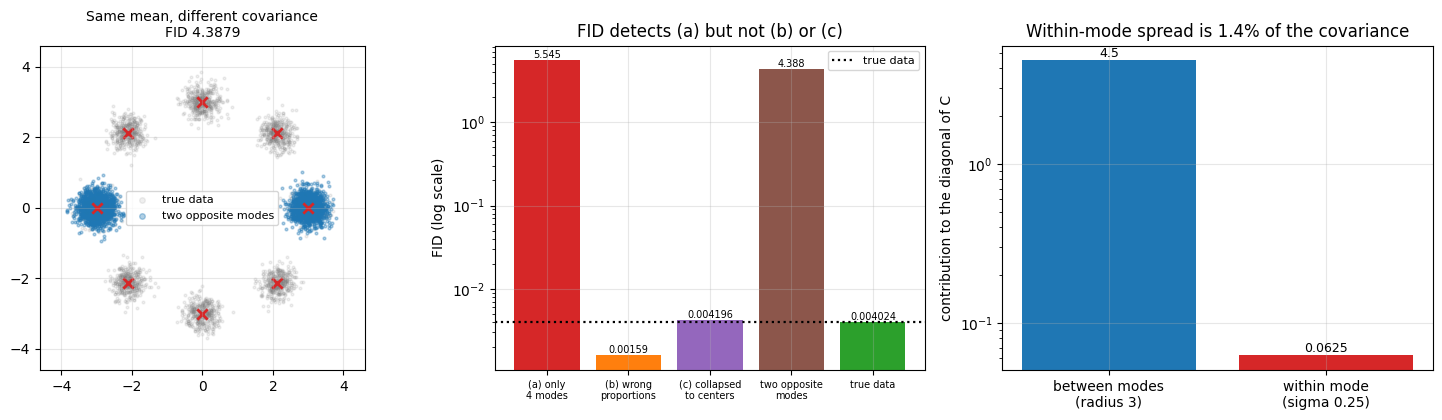

In [11]:
# ============================================================
# 図: FID の感度
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# 2モードだけの散布図
sn = TWO_MODE[:3000].numpy()
axes[0].scatter(X_ref[:3000, 0], X_ref[:3000, 1], s=4, alpha=0.12, color="tab:gray",
                label="true data")
axes[0].scatter(sn[:, 0], sn[:, 1], s=4, alpha=0.35, color="tab:blue",
                label="two opposite modes")
axes[0].scatter(RING[:, 0], RING[:, 1], s=55, marker="x", color="tab:red", lw=2)
axes[0].set_xlim(-4.6, 4.6)
axes[0].set_ylim(-4.6, 4.6)
axes[0].set_aspect("equal")
axes[0].set_title(f"Same mean, different covariance\nFID {m_two['fid']:.4f}", fontsize=10)
axes[0].legend(fontsize=8, markerscale=2)

# FID の感度
tags_s = ["(a) only\n4 modes", "(b) wrong\nproportions", "(c) collapsed\nto centers",
          "two opposite\nmodes", "true data"]
vals_s = [v for _, v in fid_sens] + [M_TRUE["fid"]]
colors_s = ["tab:red", "tab:orange", "tab:purple", "tab:brown", "tab:green"]
axes[1].bar(range(5), vals_s, color=colors_s)
axes[1].axhline(M_TRUE["fid"], color="k", ls=":", lw=1.6, label="true data")
axes[1].set_yscale("log")
axes[1].set_xticks(range(5))
axes[1].set_xticklabels(tags_s, fontsize=7)
axes[1].set_ylabel("FID (log scale)")
axes[1].set_title("FID detects (a) but not (b) or (c)")
axes[1].legend(fontsize=8)
for i, v in enumerate(vals_s):
    axes[1].text(i, v, f"{v:.4g}", ha="center", va="bottom", fontsize=7)

# 共分散への寄与
contrib = [3**2 / 2, RING_SD**2]
axes[2].bar(["between modes\n(radius 3)", f"within mode\n(sigma {RING_SD})"], contrib,
            color=["tab:blue", "tab:red"])
axes[2].set_yscale("log")
axes[2].set_ylabel("contribution to the diagonal of C")
axes[2].set_title(f"Within-mode spread is {RING_SD**2/(3**2/2+RING_SD**2)*100:.1f}% of the covariance")
for i, v in enumerate(contrib):
    axes[2].text(i, v, f"{v:.4g}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

### 読み取れること — FID は (a) にだけ強く反応する

| ケース | FID | 真のデータの何倍 | エネルギー距離の何倍（参考） |
|---|---|---|---|
| (a) 4モードのみ | 5.54549 | **1378 倍** | 704 倍 |
| (b) 比率 4:1 | 0.00159 | **0.4 倍（真より良い）** | 25 倍 |
| (c) モード中心に潰す | 0.00420 | 1.0 倍（区別できない） | 17 倍 |
| 対向2モードだけ | 4.38788 | 1091 倍 | 428 倍 |
| 真のデータ | 0.00402 | 1 倍 | 1 倍 |

**FID が検出するのは (a) 系の失敗だけ**です（4モードのみ 1378 倍、対向2モードだけ 1091 倍）。
(b) には**真のデータより良い値**を返し、(c) は真のデータと**区別できません**。

原因は共分散の内訳です。

| 寄与 | 対角成分への大きさ | 割合 |
|---|---|---|
| モード間（半径 3 の円周配置） | 4.50 | 98.6% |
| モード内（$\sigma = 0.25$） | 0.0625 | **1.4%** |

モード内の広がりは共分散の 1.4% です。それを 0 にしても
**ガウス近似の2つのモーメントはほとんど動きません**。

「平均と共分散が一致するのに分布が違う例」を作ろうとして
**対向する2モードだけ**を試しましたが、うまくいきませんでした。
2点配置では共分散が一方向に伸びてしまい（被覆 2/8、最大偏差 0.3825、FID 4.38788）、
等方的な8モードと一致させられません。
**完全に一致させるには等方的な配置が必要**で、
8モードを等方性を保ったまま減らすことはできません。
この構成は**失敗した試みとして残します**。

ただし**この例は不要でした**。(b) と (c) がすでに
「FID が真のデータと区別できない（あるいは真より良い）のに分布は違う」例に
なっているからです（FID 0.4 倍と 1.0 倍）。
等方性を厳密に保つ必要はなく、**共分散の 98.6% を占めるモード間の配置を保てば
FID は動かない**というのが実測から得られた正しい理解です。
原理的には高次元でも同じで、だから画像の FID でも同じ問題が起きます。

> 📌 **実務上の含意**: FID が良いことは「平均と共分散が合っている」ことしか意味しません。
> 多様性の欠如（同じ画像ばかり出る）は、**FID では検出できない可能性があります**。
> 併記すべきは (i) 被覆の指標、(ii) 多様性の指標（最近傍距離・precision/recall）、
> (iii) 分布距離（エネルギー距離・MMD）です。
> 本章の実測では、**4つの指標のうち3つが「問題なし」と言う分布が
> 8点にしか確率を置いていませんでした**。

<a id="summary"></a>
## 7. まとめとチートシート

### 「モード崩壊」の3つの型と、それを検出する指標

| 型 | 構成した例での値 | 検出する指標 | **検出しない指標** |
|---|---|---|---|
| **(a) 完全な取りこぼし** | 被覆 4/8、ED 1.056、FID 5.545 | 被覆率・ED・FID | 最近傍距離（0.01628、真の 0.02358 に近い） |
| **(b) 比率の誤り** | 最大偏差 0.0816、ED 0.0369 | 占有率の最大偏差・ED | **FID（0.4 倍 = 真より良い）**・被覆率 |
| **(c) 多様性の欠如** | 最近傍距離 **0.00000** | **最近傍距離のみ** | 被覆率（8/8）・最大偏差（0.0038）・**FID（1.0 倍 = 区別できない）** |

**1つの指標で分布の一致を主張してはいけません。**
本章で最も重要な1行は、(c) の行です。
**被覆率・占有率・FID の3つが「問題なし」と判定する分布が、8点にしか確率を置いていません。**
そして (b) の行も同じくらい重要です。**FID は真のデータより良い値を返しました。**

### GAN の設定と出る型（3シード平均）

| 設定 | 被覆 | 最大偏差 | 最近傍距離 | ED | 型 |
|---|---|---|---|---|---|
| 標準 | 8.0 | 0.1068 | 0.01816 | 0.09434 | (b) |
| 潜在1次元 | 8.0 | 0.1394 | **0.00190** | 0.26447 | **(c)** |
| 生成器を極小（隠れ8） | **4.7** | 0.3875 | 0.01451 | 1.59440 | **(a)** |
| D の lr を10倍 | 8.0 | 0.1489 | 0.02394 | 0.18537 | (b) |

**潜在1次元は (a) だと予想して (c) が出ました。**
1次元の潜在を2次元に写すと出力が**曲線**になり、
8モードすべての近くを通れるので被覆は満点になりますが、局所的には1次元しかありません。

### 8シードでのばらつき

| 指標 | 範囲 | 比 |
|---|---|---|
| 被覆率 | **8/8（全シード同一）** | **0** |
| 最大偏差 | 0.0786 〜 0.1395 | 1.8 倍 |
| 最近傍距離 | 0.01705 〜 0.01992 | 1.2 倍 |
| エネルギー距離 | 0.04115 〜 0.31920 | **7.8 倍** |
| FID | 0.01305 〜 1.12094 | **86 倍** |

**被覆率だけを報告する評価は、GAN の 7.8 倍の品質差を検出できません。**
そして FID は 86 倍ばらつくので、**単一シードの FID は何も保証しません**。

### 尤度ベースとの比較

| | 被覆 | 最大偏差（平均） | ED（平均） | ED（標準偏差） |
|---|---|---|---|---|
| GAN（8シード） | 8/8 全部 | 0.1066 | 0.15032 | 0.07746 |
| RealNVP（3シード） | 8/8 全部 | 0.0192 | 0.00950 | 0.00499 |
| 真のデータ | 8/8 | 0.0032 | 0.00150 | — |

ED の平均で **15.8 倍**、標準偏差で **15.5 倍**の差。
ただし**比で見ると 7.8 倍 対 3.9 倍で 2 倍程度の違いにしか見えません**。
**ばらつきは絶対値で比べる。**

### 47（MDN）との違い — 似て見えるが原因が別

| | 47 の「潰れ」 | 本章の (c) |
|---|---|---|
| 現象 | 予測が正解たちの**平均**に寄る | 生成が**同じ点**ばかりになる |
| 原因 | **損失関数の性質**（二乗誤差の最適解が条件付き平均） | **アーキテクチャ/均衡**（潜在次元の不足、敵対的学習の均衡） |
| 直し方 | 損失を変える（NLL にする）か出力を分布にする | 潜在次元を増やす、正則化、距離の定義を変える（183） |
| モデルを大きくすると | **直らない**（損失の性質なので） | 場合により直る（表現力の問題なら） |

### 次章への接続

| 章 | 本章の何を引き継ぐか |
|---|---|
| **183 WGAN-GP** | 180 の勾配消失と本章の (b) の両方に効く。距離の定義を変える |
| 184 Conditional GAN | 条件ごとの被覆を測る必要が出る（本章の指標をラベル別に適用） |
| 186 VQ-GAN | 離散表現では「使われないコード」が (a) に相当する（コードブック崩壊） |

<a id="quiz"></a>
## 8. 自己評価クイズ

### Q1: 被覆率だけを報告する評価の問題

**問題**: ある論文が「提案手法は8峰すべてを被覆した（8/8）」と報告しています。
本章の実測を根拠に、この報告から**言えないこと**を3つ挙げてください。

<details>
<summary>答えを見る</summary>

本章の実測では、**8シードすべてが 8/8 被覆**でした。それでも:

1. **品質が言えない**。同じ 8/8 のまま、エネルギー距離は 0.04115 から 0.31920 まで
   **7.8 倍**ばらつきました。
2. **比率が言えない**。標準設定の占有率は
   `[0.237, 0.054, 0.238, 0.052, 0.235, 0.062, 0.062, 0.062]` で、
   4つのモードが他の4つの**約4倍**出ています。被覆率は満点です。
3. **多様性が言えない**。構成した (c)（各モード中心に潰した分布）は
   被覆率 8/8・占有率の最大偏差 0.0038（真のデータの 0.0032 とほぼ同じ）・
   FID 0.00420（真のデータの 0.00402 と区別できない）でありながら、
   最近傍距離は **0.00000** です。8点しか出していません。

つまり被覆率は「**確率がゼロの領域があるか**」という最も粗い問いにしか答えません。
閾値（本章では 2%）を超えさえすればよいので、
0.021 と 0.24 の区別もつきません。

最低限併記すべきもの: **占有率の分布（最大偏差）**、
**多様性の指標（最近傍距離など）**、**分布距離（エネルギー距離・MMD）**、
そして**複数シードの平均と標準偏差**。
</details>

---

### Q2: FID が (c) を検出できない理由

**問題**: 本章の実測で、比率を 4:1 にずらした分布の FID は 0.00159 で、
真のデータの 0.00402 より**良い**値でした。
モード中心に潰した分布も 0.00420 で真のデータと区別できません。
なぜこうなるのかを、FID の定義から説明してください。

<details>
<summary>答えを見る</summary>

FID は2つの分布を**ガウスで近似**して比べます。

$$\mathrm{FID} = \lVert \mu_1 - \mu_2 \rVert^2
+ \mathrm{tr}\!\left(C_1 + C_2 - 2(C_1 C_2)^{1/2}\right)$$

見ているのは**平均と共分散だけ**です。

本章の設定では、共分散の内訳はこうなります。

| 寄与 | 対角成分への大きさ | 割合 |
|---|---|---|
| モード間（半径 3 の円周上の配置） | $3^2/2 = 4.50$ | 98.6% |
| モード内（$\sigma = 0.25$） | $0.25^2 = 0.0625$ | **1.4%** |

モード内の広がりを 0 にしても、共分散は **1.4% しか変わりません**。
平均は（占有率が正しいので）原点のまま変わりません。
したがって FID はほとんど動きません。

比率をずらした (b) についても同じです。配置が対称なので、
重みを 0.2 / 0.05 の交互にしても平均は原点のまま動かず、
共分散も大きくは変わりません。

「真より良い」になったのは**有限標本の効果**です。
真のデータ側も 5000 点の標本なので共分散に推定誤差があり、
失敗した分布のほうが偶然 $C_2$ に近くなりました。
つまり **0.00159 や 0.00420 と 0.00402 の差自体に意味はなく、
どちらも「検出していない」と読むのが正しい**です。

対照として、エネルギー距離は (b) で 25 倍、(c) で 17 倍動いています。
**同じ失敗に対して FID は 1 倍、エネルギー距離は 20 倍前後**です。

一般化: **多峰分布では、モード内の構造は共分散のごく一部**です。
画像の FID も Inception の特徴空間で同じガウス近似をしているので、
原理的に同じ鈍さを持ちます。
</details>

---

### Q3: 潜在1次元が (c) になった理由

**問題**: 潜在次元を1にした GAN は (a) 取りこぼしになると予想しましたが、
被覆 8/8 で (c) 多様性の欠如（最近傍距離 0.00190、真の 12分の1）になりました。
機構を説明してください。

<details>
<summary>答えを見る</summary>

生成器は $z \in \mathbb{R}^1 \mapsto x \in \mathbb{R}^2$ の連続写像です。
1次元の入力を2次元に写すので、**像は曲線**になります（面を埋めません）。

| 性質 | 曲線だとどうなるか |
|---|---|
| 被覆率 | 曲線は8つのモードすべての近くを通れる → **満点になれる** |
| 局所的な多様性 | 曲線上の点なので、近傍は1次元しかない → **最近傍距離が小さくなる** |

実測の最近傍距離 0.00190 は真のデータの 0.02358 の 12 分の 1 です。
一方、真のデータは2次元のガウス（面）なので、同じ点数でも
最近傍までの距離が大きくなります。

これは「**次元の呪い**の裏返し」です。同じ点数を1次元に並べると
密に詰まり、2次元に広げると疎になります。

実務的な帰結: **潜在次元はデータの多様体の次元以上にする**必要があります。
ただし増やしすぎれば別の問題（使われない次元、学習の難化）が出るので、
「大きければ良い」わけではありません。
本章の実測は $d=2$ のデータに対する話で、
高次元画像で同じ比率が成り立つとは限りません。
</details>

---

### Q4: ばらつきを比で報告する問題

**問題**: 本章では GAN の ED のばらつきが 7.8 倍、RealNVP が 3.9 倍でした。
「どちらも同程度にばらつく」と結論するのは正しいですか。

<details>
<summary>答えを見る</summary>

**正しくありません。** 比ではなく絶対値で比べる必要があります。

| | ED の範囲 | 比 | **標準偏差** | 平均 |
|---|---|---|---|---|
| GAN（8シード） | 0.04115 〜 0.31920 | 7.8 倍 | **0.07746** | 0.15032 |
| RealNVP（3シード） | 0.00410 〜 0.01613 | 3.9 倍 | **0.00499** | 0.00950 |

**標準偏差で 15.5 倍**違います。比が近いのは、
RealNVP の**平均が 15.8 倍小さい**からです。
良いモデルは平均が小さいので、同じ絶対ばらつきでも比は大きく出ます。

一般原則: **相対指標は分母が小さいときに膨らみます。**
ばらつきを比較するなら標準偏差（または四分位範囲）を使い、
比を使うなら必ず平均を併記します。

もう1つの注意: **範囲（最小〜最大）はシード数とともに広がります**（極値統計）。
196 の4シードでは 4.7 倍でしたが、8シードでは 7.8 倍になりました。
手法そのものが悪化したのではなく、**標本を増やせば極値が伸びる**だけです。
だから報告すべきは範囲でなく**平均と標準偏差**です。

これは 192 で「$d$ が大きいときだけ効く工夫を $d=2$ で測ると小さく見える」と
書いたのと同じ、**測り方の読み替え**の問題です。
</details>

In [12]:
# ============================================================
# 最終サマリ
# ============================================================

lines_built = "\n".join(
    f"  {t:<24} 被覆 {built[t]['cov']}/8  最大偏差 {built[t]['maxdev']:.4f}  "
    f"最近傍 {built[t]['nn']:.5f}  ED {built[t]['ed']:.5f}  FID {built[t]['fid']:.5f}"
    for t, _ in constructed)
lines_cfg = "\n".join(
    f"  {t:<24} 被覆 {gan_results[t][0]['cov']:.1f}/8  最大偏差 {gan_results[t][0]['maxdev']:.4f}  "
    f"最近傍 {gan_results[t][0]['nn']:.5f}  ED {gan_results[t][0]['ed']:.5f}"
    for t, _ in CONFIGS)
lines_seed = (f"  被覆率      すべて 8/8  -> ばらつき 0\n"
              f"  最大偏差    {min(mds):.4f} 〜 {max(mds):.4f}（{max(mds)/min(mds):.1f} 倍）\n"
              f"  最近傍距離  {min(nns):.5f} 〜 {max(nns):.5f}（{max(nns)/min(nns):.1f} 倍）\n"
              f"  ED          {min(eds):.5f} 〜 {max(eds):.5f}（{max(eds)/min(eds):.1f} 倍）"
              f" 平均 {np.mean(eds):.5f} 標準偏差 {np.std(eds):.5f}\n"
              f"  FID         {min(fids):.5f} 〜 {max(fids):.5f}（{max(fids)/min(fids):.0f} 倍）")
lines_fid = "\n".join(f"  {t:<24} FID {v:>9.5f} = 真の {v/M_TRUE['fid']:>8.1f} 倍"
                      for t, v in fid_sens)

print("=" * 78)
print("Notebook 182 完了: モード崩壊を測る")
print("=" * 78)
print(f'''
【土俵】8峰リング（半径3・sigma {RING_SD}、隣接間距離 {gap:.2f} = {gap/RING_SD:.1f}シグマ、真の占有率 各0.125）
  基準（真のサンプル）: 被覆 {M_TRUE['cov']}/8  最大偏差 {M_TRUE['maxdev']:.4f}  最近傍 {M_TRUE['nn']:.5f}  ED {M_TRUE['ed']:.5f}  FID {M_TRUE['fid']:.5f}

【構成した3つの失敗 — どの指標が何を検出するか】
{lines_built}

  -> (c) が本章の核心。被覆 8/8・最大偏差 {built['(c) モード中心に潰す']['maxdev']:.4f}（真とほぼ同じ）・
     FID {built['(c) モード中心に潰す']['fid']:.5f}（真の {built['(c) モード中心に潰す']['fid']/M_TRUE['fid']:.1f} 倍 = 真より良い）なのに
     最近傍距離は {built['(c) モード中心に潰す']['nn']:.5f}。8点にしか確率を置いていない。
     指標4つのうち3つが「問題なし」と判定した。

  予想が外れた点: FID は共分散を見るので (c) を検出すると予想したが、外れた。
  モード内の広がりは共分散の {RING_SD**2/(3**2/2+RING_SD**2)*100:.1f}% しか占めないため
  （モード間 {3**2/2:.2f} vs モード内 {RING_SD**2:.4f}）。

【GAN の設定と出る型（3シード平均）】
{lines_cfg}

  予想が外れた点: 潜在1次元は (a) 取りこぼしだと予想したが、被覆 8/8 で (c) が出た
  （最近傍 {gan_results['潜在1次元'][0]['nn']:.5f} = 真の {M_TRUE['nn']/gan_results['潜在1次元'][0]['nn']:.0f} 分の1）。
  1次元の潜在を2次元に写すと像が曲線になり、全モードの近くを通れるが
  局所的には1次元しかない。

  「GAN はモードを落とす」は標準設定では再現せず、出たのは比率の誤り (b)。
  取りこぼしが出たのは生成器を極小にしたときだけ = 表現力の不足。

【8シードでのばらつき】
{lines_seed}

  -> 被覆率だけの報告では ED の {max(eds)/min(eds):.1f} 倍の品質差を検出できない。
     FID は {max(fids)/min(fids):.0f} 倍ばらつくので単一シードの FID は何も保証しない。
     196 の4シード（4.7倍）→ 8シード（{max(eds)/min(eds):.1f}倍）。範囲はシード数とともに広がる（極値統計）。
     報告すべきは範囲でなく平均と標準偏差。

【尤度ベースとの比較】
  GAN（8シード）     : 被覆 8/8 全部  最大偏差 {np.mean(mds):.4f}  ED 平均 {np.mean(eds):.5f}  標準偏差 {np.std(eds):.5f}
  RealNVP（3シード） : 被覆 8/8 全部  最大偏差 {np.mean(f_mds):.4f}  ED 平均 {np.mean(f_eds):.5f}  標準偏差 {np.std(f_eds):.5f}
  真のデータ         : 被覆 8/8      最大偏差 {M_TRUE['maxdev']:.4f}  ED {M_TRUE['ed']:.5f}
  -> ED の平均で {np.mean(eds)/np.mean(f_eds):.1f} 倍、標準偏差で {np.std(eds)/np.std(f_eds):.1f} 倍の差。
     ただし比で見ると {max(eds)/min(eds):.1f} 倍 対 {max(f_eds)/min(f_eds):.1f} 倍で大差なく見える。
     ばらつきは絶対値（標準偏差）で比べる。

【FID の感度】
{lines_fid}
  {'真のデータ':<24} FID {M_TRUE['fid']:>9.5f} = 真の {1.0:>8.1f} 倍
  -> 強く反応するのは (a) だけ。(b) には {built['(b) 比率 4:1']['fid']/M_TRUE['fid']:.1f} 倍しか動かず、(c) には真より良い値を返す。
     FID が良いことは「平均と共分散が合っている」ことしか意味しない。

【次の章へ】
  183 WGAN-GP: 180 の勾配消失と本章の (b) 比率の誤りの両方に、距離の定義を変えて効く
''')
print("=" * 78)

Notebook 182 完了: モード崩壊を測る

【土俵】8峰リング（半径3・sigma 0.25、隣接間距離 2.30 = 9.2シグマ、真の占有率 各0.125）
  基準（真のサンプル）: 被覆 8/8  最大偏差 0.0032  最近傍 0.02358  ED 0.00150  FID 0.00402

【構成した3つの失敗 — どの指標が何を検出するか】
  真のデータ                    被覆 8/8  最大偏差 0.0032  最近傍 0.02358  ED 0.00150  FID 0.00402
  (a) 4モードのみ               被覆 4/8  最大偏差 0.1268  最近傍 0.01628  ED 1.05615  FID 5.54549
  (b) 比率 4:1               被覆 8/8  最大偏差 0.0816  最近傍 0.02097  ED 0.03685  FID 0.00159
  (c) モード中心に潰す             被覆 8/8  最大偏差 0.0038  最近傍 0.00000  ED 0.02530  FID 0.00420

  -> (c) が本章の核心。被覆 8/8・最大偏差 0.0038（真とほぼ同じ）・
     FID 0.00420（真の 1.0 倍 = 真より良い）なのに
     最近傍距離は 0.00000。8点にしか確率を置いていない。
     指標4つのうち3つが「問題なし」と判定した。

  予想が外れた点: FID は共分散を見るので (c) を検出すると予想したが、外れた。
  モード内の広がりは共分散の 1.4% しか占めないため
  （モード間 4.50 vs モード内 0.0625）。

【GAN の設定と出る型（3シード平均）】
  標準                       被覆 8.0/8  最大偏差 0.1068  最近傍 0.01816  ED 0.09434
  潜在1次元                    被覆 8.0/8  最大偏差 0.1394  最近傍 0.00190  ED 0.26447
  生成器を極小（隠れ8）              被覆 4.7/8  最大偏差 0.3875 